# 2026-06-25 OD600 — phage infection time-course (9-9-2 + p8, redo)

Lysis curves for **9-9-2** challenged with phage **p8**. In this redo the **phage is added at
t = 0** (clock 20:08) into an already-dense culture (OD ≈ 1.0), so there is no spike-in step or
mid-run dilution — it is a plain continuous timecourse. The readout is simple: do the phage tubes
**fall below the no-phage control** over time (lysis)?

## Samples (3 total)
| column | condition | phage |
|---|---|---|
| `9-9-2_control` | no-phage control | none |
| `9-9-2_1`, `9-9-2_2` | + phage | 9-9-2 p8 (2 replicates) |

## How to log data (at the bench)
Fill in [`../data/assays/0625_od600_phage(9-9-2_p8_redo).csv`](../data/assays/0625_od600_phage%289-9-2_p8_redo%29.csv)
— wide format, one row per hour: `date`, `time` (hh:mm), `t`, then one OD600 column per tube.
Leave a cell blank until that reading is taken. Re-run the notebook to refresh the plots.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("../data/assays/0625_od600_phage(9-9-2_p8_redo).csv")
OUT = Path("output/0625_od600_phage_9-9-2_redo")
OUT.mkdir(parents=True, exist_ok=True)

# Fixed experiment design — column -> metadata.
SAMPLES = pd.DataFrame([
    ("9-9-2_control", "control", "9-9-2 control", "none",     0),
    ("9-9-2_1",       "phage",   "9-9-2 +p8",     "9-9-2 p8", 1),
    ("9-9-2_2",       "phage",   "9-9-2 +p8",     "9-9-2 p8", 2),
], columns=["sample", "condition", "group", "phage", "replicate"])
SAMPLE_COLS = SAMPLES["sample"].tolist()

PHAGE_CMAP = plt.cm.Greens
def tube_color(meta):
    return "black" if meta["condition"] == "control" else PHAGE_CMAP(0.45 + 0.2 * meta["replicate"])
SAMPLES

,sample,condition,group,phage,replicate
0,9-9-2_control,control,9-9-2 control,none,0
1,9-9-2_1,phage,9-9-2 +p8,9-9-2 p8,1
2,9-9-2_2,phage,9-9-2 +p8,9-9-2 p8,2


## 1 · Load readings

Reads the wide CSV and melts it to tidy long form (`t, sample, od600`) joined to the sample
metadata. Blank cells are unrecorded readings and are dropped.

In [14]:
wide = pd.read_csv(DATA)
for c in SAMPLE_COLS:
    wide[c] = pd.to_numeric(wide[c], errors="coerce")

data = (wide.melt(id_vars=["date", "time", "t"], value_vars=SAMPLE_COLS,
                  var_name="sample", value_name="od600")
            .dropna(subset=["od600"])
            .merge(SAMPLES, on="sample", how="left")
            .sort_values(["sample", "t"]))

n_read = len(data)
print(f"{n_read} OD readings recorded across {data['sample'].nunique()}/3 tubes"
      f"{' — none yet' if n_read == 0 else ''} (phage added at t=0).")
wide

18 OD readings recorded across 3/3 tubes (phage added at t=0).


,date,time,t,9-9-2_control,9-9-2_1,9-9-2_2
0,2026-06-25,20:08,0,1.168,0.968,0.948
1,2026-06-25,21:08,1,1.175,0.964,0.983
2,2026-06-25,22:08,2,1.210,0.969,0.981
3,2026-06-25,23:08,3,1.236,1.019,1.029
4,2026-06-26,00:08,4,1.283,1.079,1.087
...,...,...,...,...,...,...
69,2026-06-28,17:08,69,NaN,NaN,NaN
70,2026-06-28,18:08,70,NaN,NaN,NaN
71,2026-06-28,19:08,71,NaN,NaN,NaN
72,2026-06-28,20:08,72,NaN,NaN,NaN


## 2 · Curves

One line per tube — control black (dashed squares), the two phage replicates green (solid
circles). Phage was in from t=0, so a phage tube dropping away from the control = lysis.

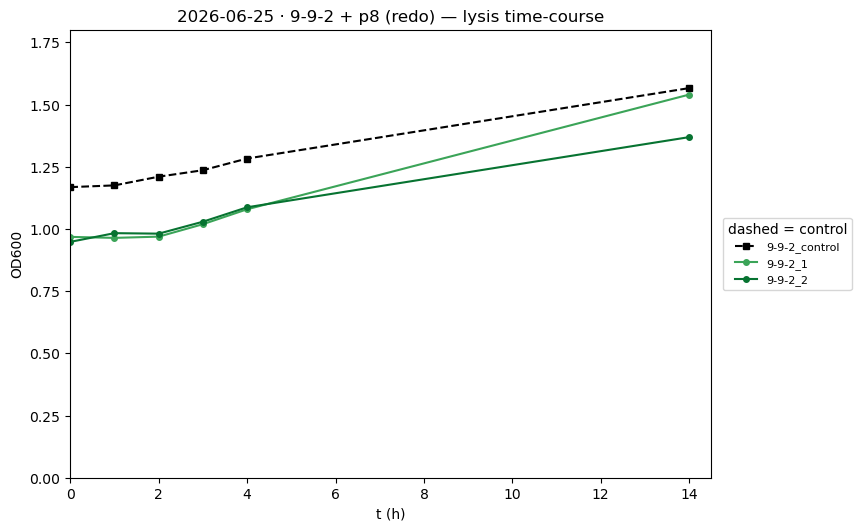

In [15]:
fig, ax = plt.subplots(figsize=(8.5, 5.2), constrained_layout=True)
for _, meta in SAMPLES.iterrows():
    sub = data[data["sample"] == meta["sample"]].sort_values("t")
    if sub.empty:
        continue
    is_ctrl = meta["condition"] == "control"
    ax.plot(sub["t"], sub["od600"], ls="--" if is_ctrl else "-",
            marker="s" if is_ctrl else "o", ms=5 if is_ctrl else 4,
            color=tube_color(meta), label=meta["sample"])

ax.set_xlabel("t (h)"); ax.set_ylabel("OD600")
ax.set_title("2026-06-25 · 9-9-2 + p8 (redo) — lysis time-course")
ax.set_xlim(0, max((data["t"].max() + 0.5) if not data.empty else 24, 6))
ax.set_ylim(0, max((data["od600"].max() * 1.15) if not data.empty else 1.3, 0.05))
ax.legend(ncol=1, fontsize=8, title="dashed = control", loc="center left",
          bbox_to_anchor=(1.01, 0.5))
fig.savefig(OUT / "2026-06-25_9-9-2_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 3 · Group means (control vs phage)

Phage replicates averaged at each hour — the clean view of whether p8 collapses the culture
relative to the no-phage control.

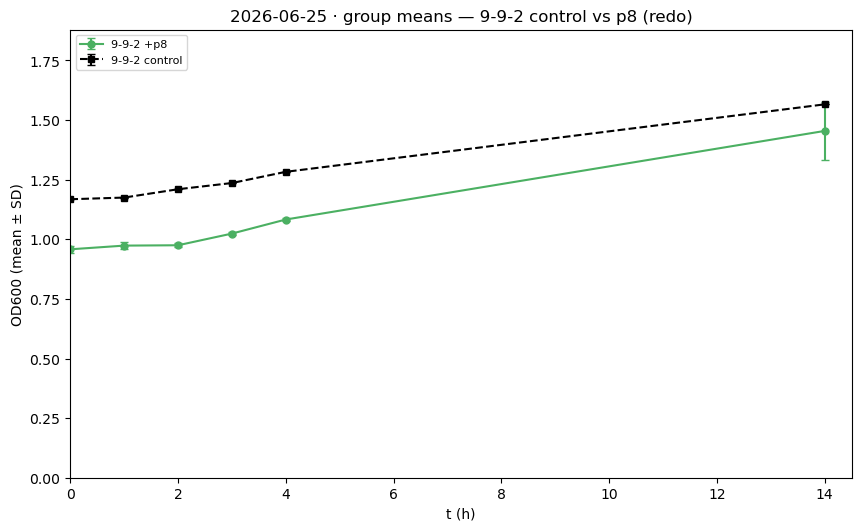

,group,condition,t,mean,std,count
0,9-9-2 +p8,phage,0,0.9580,0.014142,2
1,9-9-2 +p8,phage,1,0.9735,0.013435,2
2,9-9-2 +p8,phage,2,0.9750,0.008485,2
3,9-9-2 +p8,phage,3,1.0240,0.007071,2
4,9-9-2 +p8,phage,4,1.0830,0.005657,2
5,9-9-2 +p8,phage,14,1.4545,0.120915,2
6,9-9-2 control,control,0,1.1680,NaN,1
7,9-9-2 control,control,1,1.1750,NaN,1
8,9-9-2 control,control,2,1.2100,NaN,1
9,9-9-2 control,control,3,1.2360,NaN,1


In [16]:
if not data.empty:
    grp = (data.groupby(["group", "condition", "t"])["od600"]
               .agg(["mean", "std", "count"]).reset_index())
    fig, ax = plt.subplots(figsize=(8.5, 5.2), constrained_layout=True)
    for (g, cond), sub in grp.groupby(["group", "condition"]):
        color = "black" if cond == "control" else PHAGE_CMAP(0.6)
        ax.errorbar(sub["t"], sub["mean"], yerr=sub["std"].fillna(0),
                    marker="s" if cond == "control" else "o", ms=5, capsize=3,
                    ls="--" if cond == "control" else "-", color=color, label=g)
    ax.set_xlabel("t (h)"); ax.set_ylabel("OD600 (mean ± SD)")
    ax.set_title("2026-06-25 · group means — 9-9-2 control vs p8 (redo)")
    ax.set_xlim(0, max(grp["t"].max() + 0.5, 6))
    ax.set_ylim(0, max(grp["mean"].max() * 1.2, 0.05))
    ax.legend(loc="upper left", fontsize=8)
    fig.savefig(OUT / "2026-06-25_9-9-2_group-means.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(grp)
else:
    print("No readings yet — fill the CSV and re-run.")